In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
# from tabulate import tabulate

In [2]:
df = pd.read_excel('SOC-OCV.xlsx')   # SOC-OCV mapping to run electrical dynamics

SOC = df['SOC'].to_numpy()
OCV = df['OCV'].to_numpy()

In [4]:
Ts = 0.01  # Time step (seconds)
iter = 220000  # Ensure iter is within data range
Qb = 2.3 * 3600  # Battery capacity

Idelta = -2.3/2*np.ones(iter + 1) # Current
t = np.zeros(iter + 1)
SOC1 = np.zeros(iter + 1)       # SoC
Vocv_vec = np.zeros(iter)       #OCV
Vt = np.zeros(iter)         #terminal voltage
T1 = np.zeros(iter + 1)     # core temp
T2 = np.zeros(iter + 1)         # surface temp
Tinf = np.zeros(iter + 1)       # ambient/coolant temp
Q = np.zeros(iter)          # heat generation
data_array = np.zeros((iter + 1, 7), dtype=np.float32)

R1, R2 = 2.64, 3.46    #Thermal resistance 
Rs = 0.05               #battery resistance 
C1, C2, Cinf, dOCV = 51.9, 6.2, 10, 1e-4    #Thermal coefficient
  
Qc = 0.02               # coolant 

T1[0] = 305
T2[0] = 305
Tinf[0] = 305
SOC1[0] = SOC[2000]
t[0] = 0
T1_pred = T1[0]
data_array[0] = [Idelta[0], t[0], Qc, Tinf[0], T2[0], T1[0], T1_pred]

In [6]:
for k in range(iter):
    t[k+1] = (k+1) * Ts


    # electrical dynamics
    SOC1[k + 1] = np.clip(SOC1[k] + Ts * (-Idelta[k] / Qb), 0, 1)
    index = min(max(int(np.floor(SOC1[k] * 10000)), 0), len(OCV) - 1)
    Vocv = OCV[index]
    Vocv_vec[k] = Vocv
    Vt[k] = Vocv - Idelta[k] * Rs


    # thermal dynamics
    Q[k] = Rs * Idelta[k] ** 2 - dOCV * Idelta[k] * T1[k]
    T1[k + 1] = T1[k] + Ts * ((-(T1[k] - T2[k]) / (R1 * C1)) + (Q[k] / C1))
    T2[k + 1] = T2[k] + Ts * ((-(T2[k] - T1[k]) / (R1 * C2)) - ((T2[k] - Tinf[k]) / (R2 * C2)))
    Tinf[k + 1] = Tinf[k] + Ts * ((-(Tinf[k] - T2[k]) / (R2 * Cinf)) - (Qc / Cinf))
        
    
    
    

 

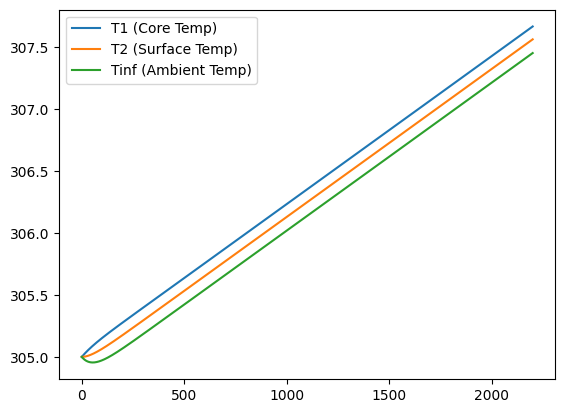

In [7]:
plt.plot(t, T1, label='T1 (Core Temp)')
plt.plot(t, T2, label='T2 (Surface Temp)')
plt.plot(t, Tinf, label='Tinf (Ambient Temp)')
plt.legend()